# Model Comparison

This notebook compares a Dummy baseline and other ML models using the same preprocessing and 5-fold cross validation on the training data. MAE is the main metric, with RMSE and R² as secondary metrics. It then looks at training and prediction times and at where the models go wrong.

## Setup

In [1]:
import sys
sys.path.append("../src")
from read_data import load_data
from preprocess import prepare_data, build_preprocessor
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from evaluation import cv_model
import matplotlib.pyplot as plt

## Load and preprocess the data

Use the same random_state=42 and 5-fold cv on all models

In [2]:
df = load_data()
X, y = prepare_data(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("Training rows:", X_train.shape)
print("Test rows:", X_test.shape)

Training rows: (429, 7)
Test rows: (108, 7)


## KNN Regressor

Test different values of k, weights and p to find the best KNN settings. 

In [3]:
knn = make_pipeline(build_preprocessor(), KNeighborsRegressor())
#range of neighbours to test
neighbours= [3, 5, 7, 11, 21]
param_grid = {"kneighborsregressor__n_neighbors": neighbours,
    "kneighborsregressor__weights": ["uniform", "distance"],
    "kneighborsregressor__p": [1, 2]
}

# GridSearchCV tries every combination. best_params_ shows the best settings
# best_score_ is the MAE scored by best_param
knn_search = GridSearchCV(knn, param_grid, cv=cv, scoring="neg_mean_absolute_error")
knn_search.fit(X_train, y_train)
print("Best KNN settings:", knn_search.best_params_)
print(f"Best KNN MAE: {-knn_search.best_score_:.2f}")



Best KNN settings: {'kneighborsregressor__n_neighbors': 11, 'kneighborsregressor__p': 1, 'kneighborsregressor__weights': 'distance'}
Best KNN MAE: 11.18


## KNN validation graph

For each number of neighbours k, show the best crossvalidation MAE found across all weight and distance values

knn
3     13.344429
5     12.358319
7     11.789850
11    11.179346
21    11.485092
Name: MAE, dtype: float64

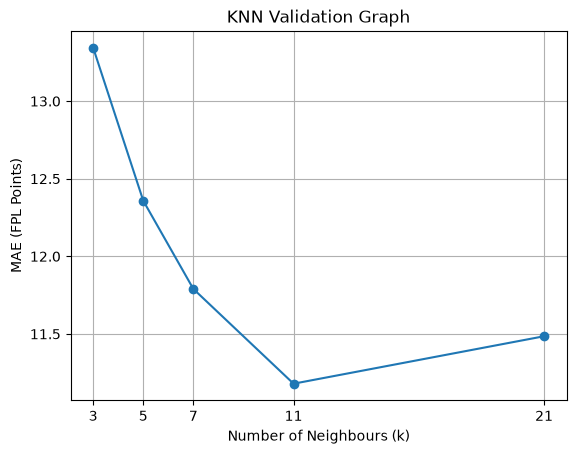

In [4]:
knn_results = pd.DataFrame(knn_search.cv_results_)
knn_results["knn"] = knn_results["param_kneighborsregressor__n_neighbors"]
knn_results["MAE"] = -knn_results["mean_test_score"]
knn_data = knn_results.groupby("knn")["MAE"].min()
display(knn_data)

knn_data.plot(marker="o")
plt.xlabel("Number of Neighbours (k)")
plt.ylabel("MAE (FPL Points)")
plt.title("KNN Validation Graph")
plt.xticks(neighbours)
plt.grid(True)
plt.show()

MAE is highest at k=3 and falls up to k=11, then rises at k=21. 
Small k overfits and large k oversmooths.
k=11 is the best balance. 

## Decision Tree Regressor 

Test different values of max depth and minimum leaf size to find the best tree settings

In [5]:
tree = make_pipeline(build_preprocessor(), DecisionTreeRegressor(random_state=42))
#Test these depth levels and leaf sizes
tree_params = {
    "decisiontreeregressor__max_depth": [3, 5, 7, 10],
    "decisiontreeregressor__min_samples_leaf": [2, 5, 10]
}

tree_search = GridSearchCV(
    tree, tree_params, cv=cv, scoring="neg_mean_absolute_error"
)
tree_search.fit(X_train, y_train)
print("Best tree settings:", tree_search.best_params_)
print(f"Best tree CV MAE: {-tree_search.best_score_:.2f}")

Best tree settings: {'decisiontreeregressor__max_depth': 10, 'decisiontreeregressor__min_samples_leaf': 10}
Best tree CV MAE: 11.80


### Decision Tree validation graph

Shows the lowest MAE at each tree depth, using the best leaf size for that depth.

depth
3     13.597785
5     12.203991
7     11.809287
10    11.803431
Name: MAE, dtype: float64

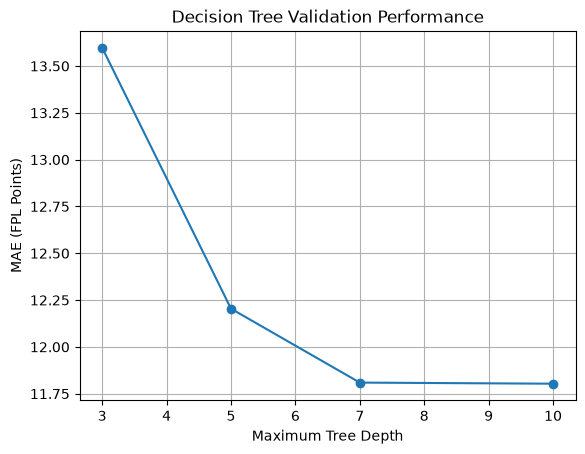

In [6]:
tree_results = pd.DataFrame(tree_search.cv_results_)
tree_results["depth"] = tree_results["param_decisiontreeregressor__max_depth"]
tree_results["MAE"] = -tree_results["mean_test_score"]
tree_data = tree_results.groupby("depth")["MAE"].min()
display(tree_data)


tree_data.plot(marker="o")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("MAE (FPL Points)")
plt.title("Decision Tree Validation Performance")
plt.grid(True)
plt.show()

MAE drops between depths 3 to 7 then levels around MAE 11.8. Increasing depth gave no improvement.

## Decision tree plot 
Plotting the top levels of the tuned tree to see which features it splits on.

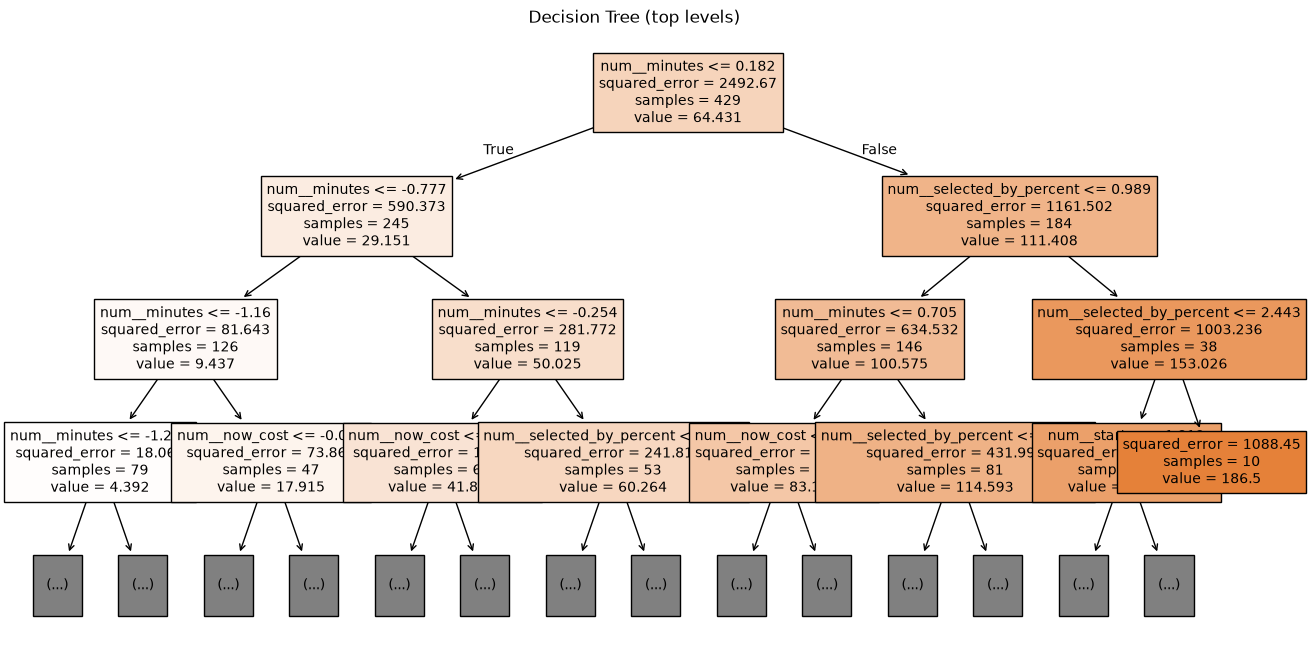

In [7]:
from sklearn.tree import plot_tree

# Get the fitted tree out of the pipeline, and the feature names after preprocessing
fitted_tree = tree_search.best_estimator_.named_steps["decisiontreeregressor"]
feature_names = tree_search.best_estimator_.named_steps["columntransformer"].get_feature_names_out()

# Plot only the top of the tree
plt.figure(figsize=(16, 8))
plot_tree(fitted_tree,
          feature_names=feature_names,
          filled=True,
          max_depth=3,
          fontsize=10)
plt.title("Decision Tree (top levels)")
plt.show()

The tree splits first on minutes in the tree, then on now_cost and selected_by_percent.

## Random Forest

Random Forest is an ensemble of many trees. Each tree gives a prediction and the forest averages them, to get a more reliable prediction.

In [8]:
# Random Forest an ensemble of many trees, averaged to reduce a single tree's instability
rf = make_pipeline(build_preprocessor(), RandomForestRegressor(random_state=42))
rf_params = {
    "randomforestregressor__n_estimators": [100, 300, 500],
    "randomforestregressor__max_features": [1.0, "sqrt"],
    "randomforestregressor__min_samples_leaf": [1, 5],
}
rf_search = GridSearchCV(rf, rf_params, cv=cv, scoring="neg_mean_absolute_error")
rf_search.fit(X_train, y_train)
print("Best RF settings:", rf_search.best_params_)
print(f"Best RF MAE: {-rf_search.best_score_:.2f}")

Best RF settings: {'randomforestregressor__max_features': 1.0, 'randomforestregressor__min_samples_leaf': 1, 'randomforestregressor__n_estimators': 500}
Best RF MAE: 9.69


trees
100    9.708350
300    9.693217
500    9.687721
Name: MAE, dtype: float64

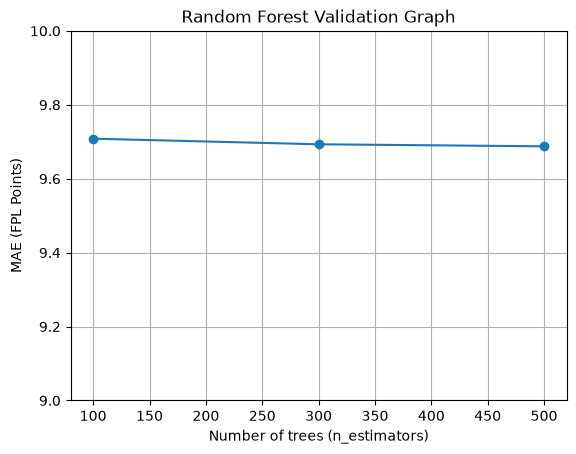

In [9]:
rf_results = pd.DataFrame(rf_search.cv_results_)
rf_results["trees"] = rf_results["param_randomforestregressor__n_estimators"]
rf_results["MAE"] = -rf_results["mean_test_score"]

# Lowest MAE for each number of trees
rf_data = rf_results.groupby("trees")["MAE"].min()
display(rf_data)

rf_data.plot(marker="o")
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("MAE (FPL Points)")
plt.title("Random Forest Validation Graph")
plt.ylim(9, 10)
plt.grid(True)
plt.show()

MAE improved by only about 0.02 between 100 and 500 trees, so 100 trees is already enough.

## Compare models against baseline

Compare models on MAE, RMSE, R² and MAE standard deviation, all under the same 5-fold
cross validation on the training data.

For KNN and the Decision Tree I use the best settings found by GridSearchCV.
Random Forest I use tts default settings of 100 trees. A grid search showed that the best settings of 500 trees only improved MAE by 0.02, which was not worth the extra training time.

In [10]:
# Build the baseline models in the same preprocessing pipeline
dummy = make_pipeline(build_preprocessor(), DummyRegressor(strategy="mean"))
linreg = make_pipeline(build_preprocessor(), LinearRegression())

In [11]:
# Run every model through the same folds
dummy_cv = cv_model(dummy,X_train,y_train)
lr_cv = cv_model(linreg,X_train,y_train)
knn_cv = cv_model(knn_search.best_estimator_, X_train, y_train)
tree_cv = cv_model(tree_search.best_estimator_, X_train, y_train)
rf_cv = cv_model(rf,X_train, y_train)

results = {
    "Dummy": dummy_cv,
    "Linear Regression": lr_cv,
    "KNN": knn_cv,
    "Decision Tree": tree_cv,
    "Random Forest": rf_cv
}

# Primary metric MAE, secondary RMSE and R2, plus MAE std for fold-to-fold variability
comparison = pd.DataFrame({
    "Model": list(results.keys()),
    "MAE":     [result["MAE"].mean()  for result in results.values()],
    "MAE_std": [result["MAE"].std()   for result in results.values()],
    "RMSE":    [result["RMSE"].mean() for result in results.values()],
    "R2":      [result["R2"].mean()   for result in results.values()],
})
display(comparison.round(2))


,Model,MAE,MAE_std,RMSE,R2
0,Dummy,41.84,2.19,49.80,-0.00
1,Linear Regression,9.85,0.72,12.89,0.93
2,KNN,11.18,0.70,15.31,0.91
3,Decision Tree,11.80,0.84,17.41,0.88
4,Random Forest,9.71,0.89,13.83,0.92


All four learned models beat the dummy baseline MAE by a wide margin.  
Random Forest has the lowest MAE, but it is only slightly better than Linear Regression.  
 Linear Regression has the lowest RMSE and the highest R², but very close to Random Forest.
kNN is next best MAE and similar R². 
The decision tree is the weakest learned model, with highest MAE.  
Random Forest has the highest MAE_std, so its score varied most between folds.
RMSE is higher than MAE for all models, which indicates some large mistakes in all models.

#### Compare training and predicting times

In [12]:
# Training and prediction costs
timing = pd.DataFrame({
    "Model": list(results.keys()),
    "Training time (secs)":   [result["fit_time"].mean() for result in results.values()],
    " Predict time (secs)": [result["score_time"].mean() for result in results.values()],
})
print(timing)

               Model  Training time (secs)   Predict time (secs)
0              Dummy              0.012500              0.007748
1  Linear Regression              0.009163              0.005431
2                KNN              0.009945              0.009450
3      Decision Tree              0.011109              0.006524
4      Random Forest              0.245180              0.012863


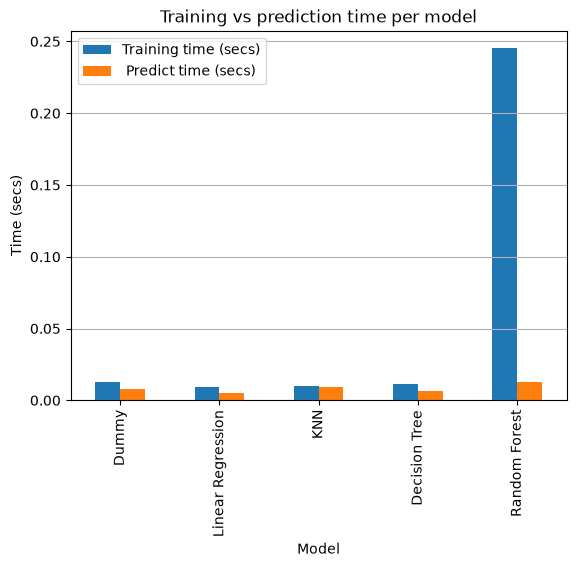

In [41]:
timing_plot = timing.set_index("Model")
timing_plot.plot(kind="bar")
plt.ylabel("Time (secs)")
plt.title("Training vs prediction time per model")
plt.grid(True, axis="y")
plt.show()

Random Forest was the slowest to train because it builds many trees. KNN and Random Forest were both slower to predict than Linear Regression and the Decision Tree. All times vary between runs, so they are only a rough guide.

## Error analysis

Error analysis looks at where the models go wrong. This code examines the learned models only.
The Knn and Decision Tree are examined using their best parameters selected after GridSearch. 
Default values are used for Random Forest and Linear regression. 

In [42]:
# Predict using the training data and cross validation
knn_best = knn_search.best_estimator_
tree_best = tree_search.best_estimator_

knn_pred = cross_val_predict(knn_best, X_train, y_train, cv=cv)
tree_pred = cross_val_predict(tree_best, X_train, y_train, cv=cv)
lr_pred = cross_val_predict(linreg, X_train, y_train, cv=cv)
rf_pred = cross_val_predict(rf, X_train, y_train, cv=cv)

#Make a table to compare actual fpl points to what was predicted by the models
errors = pd.DataFrame({
    "actual": y_train,
    "knn_pred": knn_pred,
    "tree_pred": tree_pred,
    "lr_pred": lr_pred,
    "rf_pred": rf_pred
})

display(errors.head(5))


,actual,knn_pred,tree_pred,lr_pred,rf_pred
794,49,38.207048,34.352941,46.519694,46.90
308,136,140.347254,145.058824,115.852857,139.44
551,3,6.331637,3.250000,-3.163581,3.20
287,13,17.567071,17.000000,16.168384,12.04
476,108,115.227939,132.235294,117.006919,118.14


### Worst predictions for each model
List the 5 worst for each learned model

In [43]:
#Calculate difference of real fpl points and the predictions
errors["knn_error"] = errors["knn_pred"] - errors["actual"]
errors["tree_error"] = errors["tree_pred"] - errors["actual"]
errors["lr_error"] = errors["lr_pred"] - errors["actual"]
errors["rf_error"] = errors["rf_pred"] - errors["actual"]

In [44]:
models={"KNN": "knn", "Tree": "tree", "Linear Regression": "lr", "Random Forest": "rf"}
for m in models:
    name=models[m]
    print(m," — worst 5 predictions" )
    display(errors.sort_values(f"{name}_error", key=abs, ascending=False)
                  [["actual", f"{name}_pred", f"{name}_error"]].head().round(2))

KNN  — worst 5 predictions


,actual,knn_pred,knn_error
552,235,167.85,-67.15
525,239,177.87,-61.13
505,154,101.04,-52.96
779,187,140.34,-46.66
515,135,89.00,-46.00


Tree  — worst 5 predictions


,actual,tree_pred,tree_error
525,239,140.13,-98.87
552,235,160.84,-74.16
720,116,186.55,70.55
779,187,132.24,-54.76
92,85,137.40,52.40


Linear Regression  — worst 5 predictions


,actual,lr_pred,lr_error
682,80,125.13,45.13
426,68,110.00,42.00
632,188,152.30,-35.70
175,136,100.70,-35.30
401,91,124.57,33.57


Random Forest  — worst 5 predictions


,actual,rf_pred,rf_error
292,177,128.73,-48.27
552,235,186.86,-48.14
525,239,195.29,-43.71
449,109,66.99,-42.01
426,68,109.58,41.58


Players 525 and 552 have very high FPL points and were under predicted by KNN, the Decision Tree and Random Forest. KNN's worst five are all high point players. The Decision Tree makes large under prediction and over prediction errors, with the largest single error (99 points). Random Forest made fewer very large errors than the tree. For players 525 and 552 it was out by about 44 to 48 points, compared with 99 and 74 for the tree. Linear Regression also over predicts and under predicts some players, but its five largest errors are smaller than those of KNN and the Decision Tree, and similar in size to Random Forests.

### Error analysis by point bands
Group players into low, medium and high fpl points and show the average error for each band.

In [45]:
print("Training set points range:")
print("min:", y_train.min())
print("max:", y_train.max())
print("count:", len(y_train))
print(y_train.describe())

Training set points range:
min: 0
max: 239
count: 429
count    429.000000
mean      64.431235
std       49.984933
min        0.000000
25%       17.000000
50%       56.000000
75%      103.000000
max      239.000000
Name: total_points, dtype: float64


In [ ]:
# Slice the errors into fpl point bands from low, medium and high scorers
max_value=errors["actual"].max()
bands = pd.cut(errors["actual"],
               bins=[0, 30, 80, max_value],
               labels=["Low (0-30)", "Medium (30-80)", "High (80+)"])
bands = bands.rename("Band")

print("Average error per band. Negative shows under prediction and positive shows over prediction")
display(errors.groupby(bands)[["knn_error", "tree_error","lr_error", "rf_error"]].mean().round(2))


Average error per band. Negative shows under prediction and positive shows over prediction


,knn_error,tree_error,lr_error,rf_error
Band,,,,
Low (0-30),4.01,1.76,2.40,1.67
Medium (30-80),-0.24,2.77,1.65,2.93
High (80+),-11.87,-4.77,-3.67,-5.34


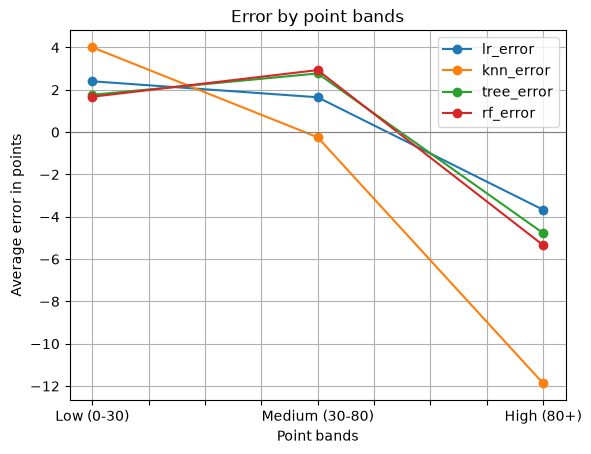

In [49]:
average_errors = errors.groupby(bands)[["lr_error", "knn_error", "tree_error", "rf_error"]].mean()

average_errors.plot(marker="o")
plt.axhline(0, color="grey", linewidth=0.8)  
plt.ylabel("Average error in points")
plt.xlabel("Point bands")
plt.title("Error by point bands")
plt.grid(True)
plt.show()

This graph shows how the models differ. All four models over predict low fpl points slightly and under predict high points. kNN is worst for high points (about −12 points). Random Forest and the single decision tree are very closely matched and under predict high points by about 5 points, slightly more than Linear Regression. Averaging many trees did not improve the under prediction of top points. 
KNN and the tree models predict averages, so they cannot predict above the scores they average and under predict the top points. 

## Conclusion

I compared five models using five-fold cross validation: Dummy Regressor, Linear Regression, KNN, Decision Tree and Random Forest.

All four learned models were much better than the Dummy baseline. Random Forest had the lowest MAE (9.71) but was only slightly better than Linear Regression (9.85), which had the better RMSE and R². KNN and the Decision Tree were weaker. Random Forest improved on the single Decision Tree by about 2 MAE points, but it did not meaningfully beat the simpler Linear Regression, and it was much slower to train.

When I looked at the prediction errors, I found that all four models tended to under predict players with high FPL points (80+). This was worst with KNN, which under predicted these players by about 12 points on average. This shows the models find high point players harder to predict.

### Best Model Settings
- **Linear Regression:** Default settings, no tuning needed.
- **Random Forest:** Default settings (100 trees). Tuning gave almost no improvement (MAE 9.69 vs 9.71).
- **KNN:** 11 neighbours, Manhattan distance (p=1), distance weighting.
- **Decision Tree:** Maximum depth 10, minimum samples per leaf 10.
- **Dummy Regressor:** Mean strategy. This was the baseline model.

My next step is to try a small neural network (MLP) .